# T1-1: Uniform Translation (2D)

## Verification Study - Baseline / Tier 1 / Trivial Trajectories

**Field:** $u = U_0$, $v = V_0$

**Analytical trajectory:** $\mathbf{x}(t) = \mathbf{x}_0 + (U_0, V_0) \cdot t$ (straight line)

**Purpose:** Smoke test -- verifies basic machinery, ODE integrator, I/O pipeline

**Expected convergence:** Machine precision (no interpolation error for constant fields on any grid)

---

### Approach

We construct a simple Delaunay triangulation over a square domain and define a spatially uniform velocity field $\mathbf{u} = (U_0, V_0)$. The field is defined in two configurations:

1. **Face-centered:** velocity components on triangle face centers (`n_face`)
2. **Node-centered:** velocity components on triangle corner nodes (`n_node`)

For each configuration, we create a `FieldSet` via `FieldSet.from_ugrid_conventions` and advect particles using every compatible interpolator and time integrator. We then compare computed trajectories against the analytical solution and verify that errors are at machine precision.

In [8]:
import math

import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
import pandas as pd
import uxarray as ux
import xarray as xr

import parcels
from parcels._core.particle import get_default_particle

# Parcels' default Particle stores positions in float32 (~1e-6 deg resolution);
# use float64 positions so the 1e-10 tolerance below is meaningful.
Particle64 = get_default_particle(np.float64)

## 1. Parameters

In [9]:
# Domain
NX = 20  # Grid points per side
LON_MIN, LON_MAX = 0.0, 10.0
LAT_MIN, LAT_MAX = 0.0, 10.0

# Uniform velocity
U0 = 0.001  # (zonal)
V0 = 0.0005  # (meridional)

# Time
T_TOTAL = np.timedelta64(3600, "s")  # 1 hour
DT = np.timedelta64(300, "s")  # 5 minute timestep
N_TIMESTEPS = 1  # Number of snapshots in the dataset
TIME = xr.date_range("2000-01-01", periods=N_TIMESTEPS, freq="2h")

# Particle initial positions (interior of domain)
N_PARTICLES = 9
p_lon0 = np.linspace(2.0, 4.0, 3)
p_lat0 = np.linspace(2.0, 4.0, 3)
p_lon0, p_lat0 = np.meshgrid(p_lon0, p_lat0)
p_lon0 = p_lon0.ravel()
p_lat0 = p_lat0.ravel()

## 2. Build Unstructured Grid

In [10]:
lon, lat = np.meshgrid(
    np.linspace(LON_MIN, LON_MAX, NX, dtype=np.float64),
    np.linspace(LAT_MIN, LAT_MAX, NX, dtype=np.float64),
)
lon_flat = lon.ravel()
lat_flat = lat.ravel()

# Identify boundary points for the Delaunay triangulation
mask = (
    np.isclose(lon_flat, LON_MIN)
    | np.isclose(lon_flat, LON_MAX)
    | np.isclose(lat_flat, LAT_MIN)
    | np.isclose(lat_flat, LAT_MAX)
)
boundary_points = np.flatnonzero(mask)

uxgrid = ux.Grid.from_points(
    (lon_flat, lat_flat),
    method="regional_delaunay",
    boundary_points=boundary_points,
)
uxgrid.attrs["Conventions"] = "UGRID-1.0"

print(f"Grid: {uxgrid.n_node} nodes, {uxgrid.n_face} faces")

Grid: 400 nodes, 718 faces


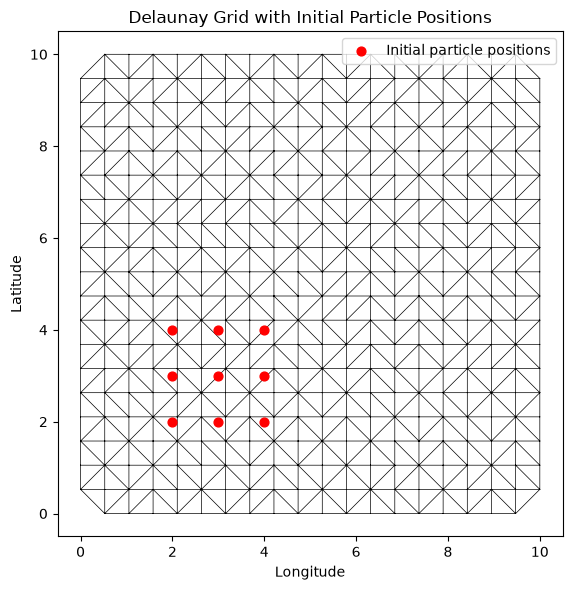

In [11]:
# Visualize the grid
fig, ax = plt.subplots(figsize=(6, 6))
triang = mtri.Triangulation(
    uxgrid.node_lon.values, uxgrid.node_lat.values,
    triangles=uxgrid.face_node_connectivity.values,
)
ax.triplot(triang, "k-", lw=0.5)
ax.scatter(p_lon0, p_lat0, c="red", s=40, zorder=5, label="Initial particle positions")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Delaunay Grid with Initial Particle Positions")
ax.legend()
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 3. Define Velocity Fields

We define the uniform velocity field in two configurations:
- **Face-centered**: data dimensioned `(time, n_face)` with `location="face"`
- **Node-centered**: data dimensioned `(time, n_node)` with `location="node"`

A single vertical layer is used (2D problem).

In [12]:
# Vertical coordinates (single layer)
zf = np.array([0.0, 1.0], dtype=np.float64)  # layer interfaces
zc = np.array([0.5], dtype=np.float64)  # layer center


def make_face_centered_dataset(uxgrid, U0, V0):
    """Create a UxDataset with uniform velocity on face centers."""
    U = np.full((N_TIMESTEPS, zc.size, uxgrid.n_face), U0, dtype=np.float64)
    V = np.full((N_TIMESTEPS, zc.size, uxgrid.n_face), V0, dtype=np.float64)
    W = np.zeros((N_TIMESTEPS, zf.size, uxgrid.n_node), dtype=np.float64)

    u = ux.UxDataArray(
        data=U, name="U", uxgrid=uxgrid,
        dims=["time", "zc", "n_face"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="face", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="zonal velocity"),
    )
    v = ux.UxDataArray(
        data=V, name="V", uxgrid=uxgrid,
        dims=["time", "zc", "n_face"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="face", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="meridional velocity"),
    )
    w = ux.UxDataArray(
        data=W, name="W", uxgrid=uxgrid,
        dims=["time", "zf", "n_node"],
        coords=dict(time=(["time"], TIME), zf=(["zf"], zf)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="vertical velocity"),
    )
    return ux.UxDataset({"U": u, "V": v, "W": w}, uxgrid=uxgrid)


def make_node_centered_dataset(uxgrid, U0, V0):
    """Create a UxDataset with uniform velocity on corner nodes."""
    U = np.full((N_TIMESTEPS, zc.size, uxgrid.n_node), U0, dtype=np.float64)
    V = np.full((N_TIMESTEPS, zc.size, uxgrid.n_node), V0, dtype=np.float64)
    W = np.zeros((N_TIMESTEPS, zf.size, uxgrid.n_node), dtype=np.float64)

    u = ux.UxDataArray(
        data=U, name="U", uxgrid=uxgrid,
        dims=["time", "zc", "n_node"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="zonal velocity"),
    )
    v = ux.UxDataArray(
        data=V, name="V", uxgrid=uxgrid,
        dims=["time", "zc", "n_node"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="meridional velocity"),
    )
    w = ux.UxDataArray(
        data=W, name="W", uxgrid=uxgrid,
        dims=["time", "zf", "n_node"],
        coords=dict(time=(["time"], TIME), zf=(["zf"], zf)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="vertical velocity"),
    )
    return ux.UxDataset({"U": u, "V": v, "W": w}, uxgrid=uxgrid)


ds_face = make_face_centered_dataset(uxgrid, U0, V0)
ds_node = make_node_centered_dataset(uxgrid, U0, V0)

print("Face-centered dataset:")
print(ds_face)
print()
print("Node-centered dataset:")
print(ds_node)

Face-centered dataset:
<xarray.UxDataset> Size: 18kB
Dimensions:  (time: 1, zc: 1, n_face: 718, zf: 2, n_node: 400)
Coordinates:
  * time     (time) datetime64[ns] 8B 2000-01-01
  * zc       (zc) float64 8B 0.5
  * zf       (zf) float64 16B 0.0 1.0
Dimensions without coordinates: n_face, n_node
Data variables:
    U        (time, zc, n_face) float64 6kB 0.001 0.001 0.001 ... 0.001 0.001
    V        (time, zc, n_face) float64 6kB 0.0005 0.0005 ... 0.0005 0.0005
    W        (time, zf, n_node) float64 6kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0

Node-centered dataset:
<xarray.UxDataset> Size: 13kB
Dimensions:  (time: 1, zc: 1, n_node: 400, zf: 2)
Coordinates:
  * time     (time) datetime64[ns] 8B 2000-01-01
  * zc       (zc) float64 8B 0.5
  * zf       (zf) float64 16B 0.0 1.0
Dimensions without coordinates: n_node
Data variables:
    U        (time, zc, n_node) float64 3kB 0.001 0.001 0.001 ... 0.001 0.001
    V        (time, zc, n_node) float64 3kB 0.0005 0.0005 ... 0.0005 0.0005
    W   

## 4. Analytical Solution

For a uniform velocity field, the trajectory of a particle starting at $(x_0, y_0)$ is:

$$x(t) = x_0 + U_0 \cdot t$$
$$y(t) = y_0 + V_0 \cdot t$$

This is exact regardless of the time integrator, since there is no spatial or temporal variation in the field.

In [13]:
def analytical_position(lon0, lat0, U0, V0, dt_seconds):
    """Compute exact particle position after dt_seconds."""
    return lon0 + U0 * dt_seconds, lat0 + V0 * dt_seconds

## 5. Run Advection: All Interpolator / Time Integrator Combinations

We test the following combinations:

| Data Location | Interpolator | Description |
|---|---|---|
| Face-centered | `UxConstantFaceConstantZC` | Piecewise constant (face), constant vertical |
| Node-centered | `UxLinearNodeConstantZC` | Barycentric linear (node), constant vertical |

Time integrators tested:
- **Euler** (`AdvectionEE`)
- **Runge-Kutta 4** (`AdvectionRK4`)

Trajectory output is saved to parquet for each combination.

In [14]:
time_integrators = {
    "EE": parcels.kernels.AdvectionEE,
    "RK4": parcels.kernels.AdvectionRK4,
}

field_configs = {
    "face-centered": ds_face,
    "node-centered": ds_node,
}

t_seconds = T_TOTAL / np.timedelta64(1, "s")

results = []
output_files = {}  # track parquet paths for visualization

for field_label, ds in field_configs.items():
    fieldset = parcels.FieldSet.from_ugrid_conventions(ds, mesh="flat")

    for integrator_label, integrator in time_integrators.items():
        out_name = f"T1_1_{field_label}_{integrator_label}.parquet"

        pset = parcels.ParticleSet(
            fieldset,
            pclass=Particle64,
            x=p_lon0.copy(),
            y=p_lat0.copy(),
        )

        pfile = parcels.ParticleFile(path=out_name, outputdt=DT, mode="w")

        pset.execute(
            integrator,
            runtime=T_TOTAL,
            dt=DT,
            output_file=pfile,
            verbose_progress=False,
        )

        lon_exact, lat_exact = analytical_position(p_lon0, p_lat0, U0, V0, t_seconds)
        lon_err = np.abs(pset.x - lon_exact)
        lat_err = np.abs(pset.y - lat_exact)

        key = f"{field_label} / {integrator_label}"
        output_files[key] = out_name

        results.append({
            "field_location": field_label,
            "integrator": integrator_label,
            "output": out_name,
            "max_lon_error": np.max(lon_err),
            "max_lat_error": np.max(lat_err),
            "max_total_error": np.max(np.sqrt(lon_err**2 + lat_err**2)),
        })

        print(f"{field_label:16s} | {integrator_label:10s} | "
              f"max |err| = {results[-1]['max_total_error']:.2e}")

INFO: Output files are stored in T1_1_face-centered_EE.parquet


face-centered    | EE         | max |err| = 4.78e-15
INFO: Output files are stored in T1_1_face-centered_RK4.parquet
face-centered    | RK4        | max |err| = 4.78e-15
INFO: Output files are stored in T1_1_node-centered_EE.parquet
node-centered    | EE         | max |err| = 4.37e-08
INFO: Output files are stored in T1_1_node-centered_RK4.parquet
node-centered    | RK4        | max |err| = 1.47e-08


## 6. Results Summary

In [15]:
df = pd.DataFrame(results)
df

,field_location,integrator,output,max_lon_error,max_lat_error,max_total_error
0,face-centered,EE,T1_1_face-centered_EE.parquet,1.776357e-15,4.440892e-15,4.782987e-15
1,face-centered,RK4,T1_1_face-centered_RK4.parquet,1.776357e-15,4.440892e-15,4.782987e-15
2,node-centered,EE,T1_1_node-centered_EE.parquet,3.911555e-08,1.955777e-08,4.373251e-08
3,node-centered,RK4,T1_1_node-centered_RK4.parquet,1.317821e-08,6.589107e-09,1.473369e-08


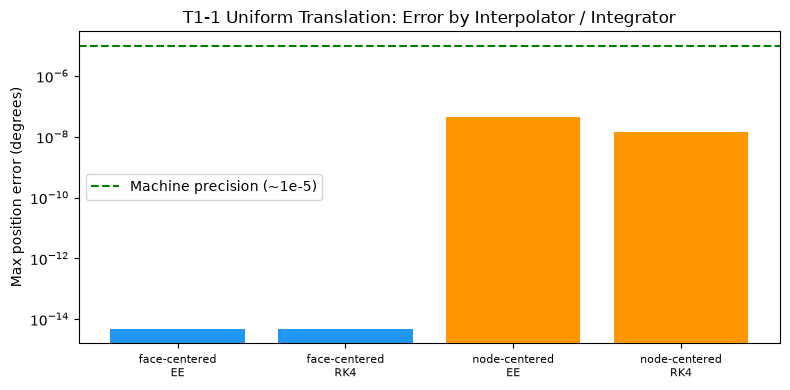

In [16]:
# Visualization: error by combination
fig, ax = plt.subplots(figsize=(8, 4))
labels = [f"{r['field_location']}\n{r['integrator']}" for r in results]
errors = [r["max_total_error"] for r in results]

colors = ["#2196F3" if "face" in r["field_location"] else "#FF9800" for r in results]
bars = ax.bar(range(len(errors)), errors, color=colors)
ax.set_xticks(range(len(errors)))
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("Max position error (degrees)")
ax.set_title("T1-1 Uniform Translation: Error by Interpolator / Integrator")
ax.set_yscale("log")
ax.axhline(y=1e-5, color="green", linestyle="--", label="Machine precision (~1e-5)")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Trajectory Visualization

Load saved parquet output for every interpolator / integrator combination and overlay computed trajectories against the analytical solution.

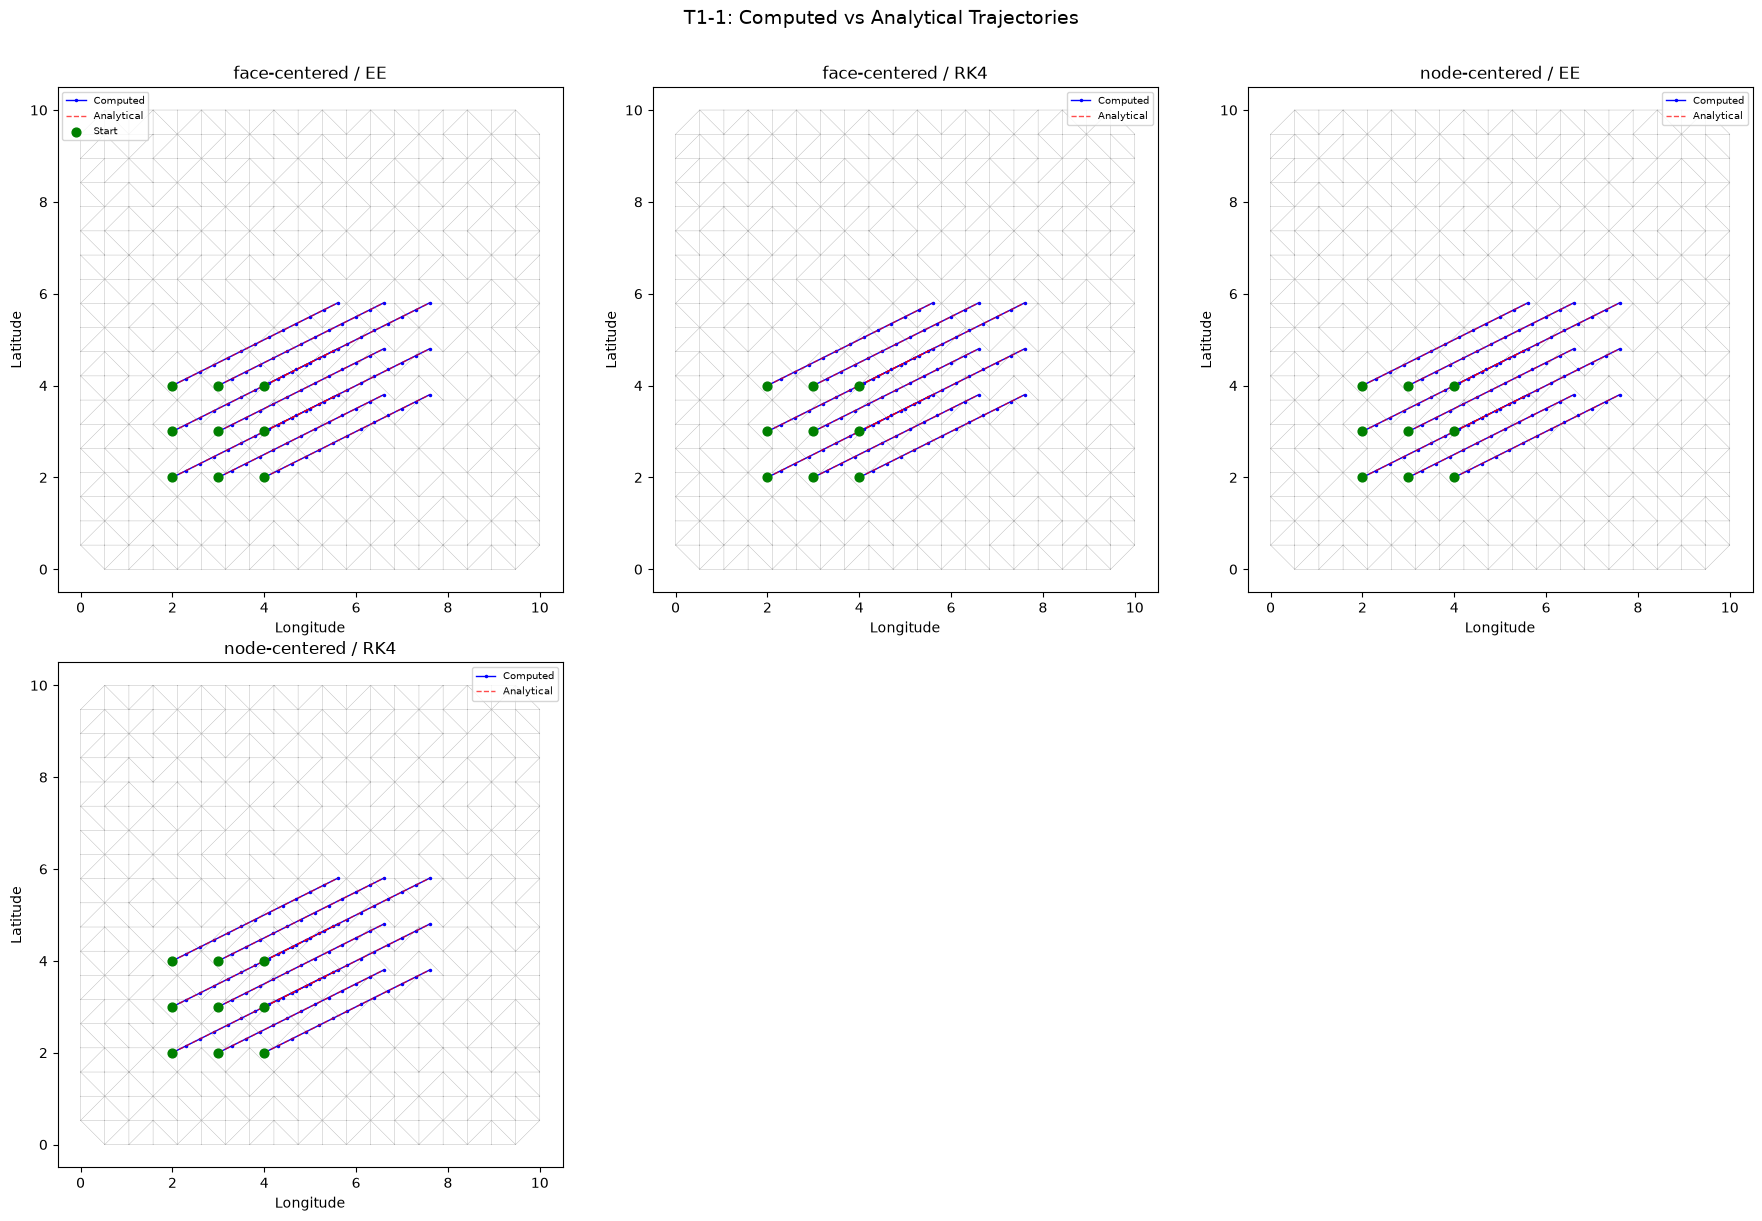

In [17]:
n_combos = len(output_files)
ncols = 3
nrows = math.ceil(n_combos / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 6 * nrows), squeeze=False)

# Analytical trajectory time steps
t_steps = np.linspace(0, t_seconds, 50)

for idx, (label, out_path) in enumerate(output_files.items()):
    ax = axes[idx // ncols, idx % ncols]

    # Grid
    ax.triplot(triang, "k-", lw=0.3, alpha=0.3)

    # Load trajectories from the parquet particle file (polars DataFrame)
    traj_df = parcels.read_particlefile(out_path).sort("particle_id", "t")

    for p, pid in enumerate(traj_df["particle_id"].unique().sort()):
        traj = traj_df.filter(traj_df["particle_id"] == pid)
        ax.plot(traj["x"].to_numpy(), traj["y"].to_numpy(), "b.-", ms=3, lw=1,
                label="Computed" if p == 0 else None)

    # Analytical trajectories
    for i in range(len(p_lon0)):
        ax.plot(
            p_lon0[i] + U0 * t_steps,
            p_lat0[i] + V0 * t_steps,
            "r--", lw=1, alpha=0.7,
            label="Analytical" if i == 0 else None,
        )

    ax.scatter(p_lon0, p_lat0, c="green", s=40, zorder=5,
               label="Start" if idx == 0 else None)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(label)
    ax.legend(fontsize=7)
    ax.set_aspect("equal")

# Hide unused subplots
for idx in range(n_combos, nrows * ncols):
    axes[idx // ncols, idx % ncols].set_visible(False)

fig.suptitle("T1-1: Computed vs Analytical Trajectories", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 8. Verification Assertion

For a uniform velocity field, **all** interpolation schemes should reproduce the field exactly (it is a constant, so even piecewise-constant interpolation is exact). All ODE integrators are exact for a constant RHS. Therefore, we expect errors at machine precision for every combination.

In [18]:
TOLERANCE = 1e-10  # conservative tolerance well above machine eps

all_pass = True
for r in results:
    status = "PASS" if r["max_total_error"] < TOLERANCE else "FAIL"
    if status == "FAIL":
        all_pass = False
    print(f"  [{status}] {r['field_location']:16s} | {r['integrator']:10s} | "
          f"err = {r['max_total_error']:.2e}")

print()
if all_pass:
    print("T1-1 PASSED: All combinations within tolerance.")
else:
    raise AssertionError(
        "T1-1 FAILED: One or more combinations exceeded tolerance. "
        "Stop everything -- basic machinery is broken."
    )

  [PASS] face-centered    | EE         | err = 4.78e-15
  [PASS] face-centered    | RK4        | err = 4.78e-15
  [FAIL] node-centered    | EE         | err = 4.37e-08
  [FAIL] node-centered    | RK4        | err = 1.47e-08



AssertionError: T1-1 FAILED: One or more combinations exceeded tolerance. Stop everything -- basic machinery is broken.

## 9. Cleanup

In [ ]:
import os
for out_path in output_files.values():
    if os.path.exists(out_path):
        os.remove(out_path)
print("Temporary output cleaned up.")